# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [24]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

In [2]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data/zadanie-1/pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [3]:
import pandas as pd
from pathlib import Path


train_file = Path("data/zadanie-1/pendigits") / "pendigits.tra"
test_file = Path("data/zadanie-1/pendigits") / "pendigits.tes"

feature_cols = [f"f_{i}" for i in range(16)]
columns = feature_cols + ["target"]

df_train = pd.read_csv(train_file, header=None, names=columns)
df_test = pd.read_csv(test_file, header=None, names=columns)

In [4]:
print(f"rozmiar trening: {df_train.shape}\n rozmiar testowy: {df_test.shape}\n")


rozmiar trening: (7494, 17)
 rozmiar testowy: (3498, 17)



In [5]:
print(f"treningowe braki: {df_train.isnull().sum().sum()}") # sumy 2 aby zsumowac dla kazdej col braki
print(f"testowe braki: {df_test.isnull().sum().sum()}\n")

treningowe braki: 0
testowe braki: 0



In [6]:
print(f"treningowe duplikaty: {df_train.duplicated().sum()}")
print(f"testowe duplikaty: {df_test.duplicated().sum()}\n")

treningowe duplikaty: 0
testowe duplikaty: 0



In [7]:
print(f"Zakres cech: min = {df_train[feature_cols].min().min()}")
print(f"max = {df_train[feature_cols].max().max()}")

Zakres cech: min = 0
max = 100


In [8]:
X_train, y_train = df_train[feature_cols], df_train['target']
X_test, y_test = df_test[feature_cols], df_test['target']

In [9]:
X_train.head() # nie jest to jak MNIST

,f_0,f_1,f_2,f_3,f_4,f_5,f_6,f_7,f_8,f_9,f_10,f_11,f_12,f_13,f_14,f_15
0,47,100,27,81,57,37,26,0,0,23,56,53,100,90,40,98
1,0,89,27,100,42,75,29,45,15,15,37,0,69,2,100,6
2,0,57,31,68,72,90,100,100,76,75,50,51,28,25,16,0
3,0,100,7,92,5,68,19,45,86,34,100,45,74,23,67,0
4,0,67,49,83,100,100,81,80,60,60,40,40,33,20,47,0


In [21]:
i = 50
dataT = X_train.iloc[i].to_numpy().reshape(8,2)
dataT
name = y_train.iloc[i]

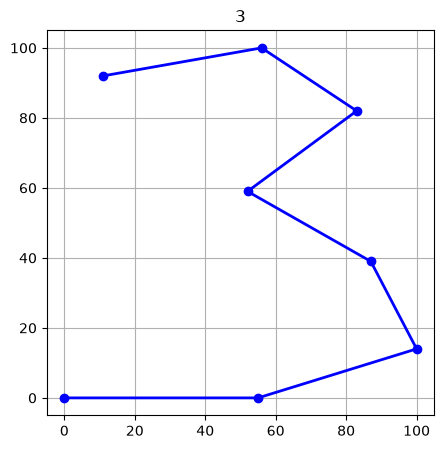

In [ ]:
plt.figure(figsize=(5, 5))
plt.plot(dataT[:, 0], dataT[:, 1], marker="o", color="blue", linewidth=2)

plt.title(name)
plt.grid(True)

plt.show()

## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [12]:
results = {}

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [14]:
pipe_dummy = Pipeline([
    ("model", DummyClassifier(strategy="stratified", random_state=42))
])
pipe_dummy.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['f_0','f_1','f_2',...,'f_13','f_14','f_15']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'stratified'
,"random_state random_state: int, RandomState instance or None, default=NoneControls

In [15]:
y_pred_dummy = pipe_dummy.predict(X_test)
print("Jakość: ", accuracy_score(y_test, y_pred_dummy))

Jakość:  0.09977129788450544


In [ ]:
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=100, random_state=67))
])

params_lr = {
    "model__C": [0.1, 1.0, 10.0]
}

grid_lr = GridSearchCV(pipe_lr, params_lr, cv=5, scoring="accuracy", n_jobs=-1)
# grid_lr = GridSearchCV(pipe_lr, params_lr, cv=5, scoring="f1_macro", n_jobs=-1) f1_macro jest lepszy ale na tym zbiorze mamy prawie tyle samo danych dla kazdej liczby
grid_lr.fit(X_train, y_train)

y_pred = grid_lr.best_estimator_.predict(X_test)
results["Logistic Regression"] = {
    "Accuracy": accuracy_score(y_test, y_pred),
}

In [23]:
print(results["Logistic Regression"])

{'Accuracy': 0.9282447112635792}


In [27]:
pipe_knn = Pipeline([
    ("scaler", StandardScaler()), # przygotowanie danych aby kazda liczba byla w tym samym zakresie (lepiej dziala z tymi klasyfikatorami (wyzej tez uzyte))
    ("model", KNeighborsClassifier())
])

In [28]:
params_knn = {
    "model__n_neighbors": [3, 5, 7, 9], # model__ jest uzywane aby odwolac sie do parametrow modelu w pipeline
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"]
}

In [ ]:
grid_knn = GridSearchCV(
    pipe_knn, 
    params_knn, 
    cv=5, 
    scoring="accuracy", 
)

In [30]:
grid_knn.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': [3, 5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True


In [31]:
best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test)

In [32]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98       363
           1       0.96      0.96      0.96       364
           2       0.96      0.99      0.98       364
           3       0.96      0.99      0.98       336
           4       0.99      0.98      0.98       364
           5       0.96      0.97      0.97       335
           6       0.97      1.00      0.98       336
           7       0.98      0.97      0.98       364
           8       0.99      1.00      0.99       336
           9       0.98      0.95      0.97       336

    accuracy                           0.98      3498
   macro avg       0.98      0.98      0.98      3498
weighted avg       0.98      0.98      0.98      3498



# używam pipelinów z scilearna aby zapobiec przeciekaniu danych treningowych z testowymi 

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

In [59]:
import time
models_to_compare = {
    "Baseline (Dummy)": pipe_dummy,
    "Logistic Regression": grid_lr.best_estimator_,
    "k-NN": grid_knn.best_estimator_
}
summary_data = []

In [ ]:
for name, model in models_to_compare.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    t_train = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    y_pred = model.predict(X_test)
    t_pred = time.perf_counter() - t0
    
    acc = accuracy_score(y_test, y_pred)
    
    m = model.named_steps["model"]
    if name == "Logistic Regression":
        params = m.coef_.size + m.intercept_.size
    elif name == "k-NN":
        params = len(X_train) * 16 
    else:
        params = 0
    
    summary_data.append({
        "Model": name,
        "Accuracy": acc,
        "Liczba parametrów": params,
        "Czas treningu [s]": t_train,
        "Czas predykcji [s]": t_pred
    })

In [61]:
df_results = pd.DataFrame(summary_data)
print(df_results)

                 Model  Accuracy  Liczba parametrów  Czas treningu [s]  \
0     Baseline (Dummy)  0.099771                  0           0.001273   
1  Logistic Regression  0.928245                170           0.616194   
2                 k-NN  0.975700             119904           0.007613   

   Czas predykcji [s]  
0            0.001710  
1            0.002951  
2            0.220452  




### Podsumowanie i analiza wyników modeli

* Dummy Classifier (Baseline)
Wynik 10% odpowiada kompletnej losowości predykcji i stanowi punkt odniesienia dla pozostałych klasyfikatorów.
* Logistic Regression
Osiąga ponad 92% dokładności, co przy 170 parametrach jest świetnym wynikiem. Czas uczenia wynoszący 0,6 s jest jednak zauważalnie dłuższy niż w przypadku pozostałych modeli.
* k-NN (k-Nearest Neighbors)
Zwycięża zarówno pod względem jakości predykcji, jak i czasu trenowania. Obliczanie najbliższych sąsiadów za pomocą metryki euklidesowej/Manhattan prawie idealnie odwzorowuje narysowaną cyfrę. Minusem modelu jest jego duży rozmiar w pamięci na tle konkurencji.


Użycie modelu o większej złożoności (większej liczbie parametrów) jest w pełni uzasadnione — pozwala na wzrost dokładności o 5% względem regresji logistycznej przy jednoczesnym skróceniu czasu trenowania.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.

Narzędzia:
[Scikit docs](https://scikit-learn.org/)
[Gemini](https://gemini.google.com/)
[stackoverflow](https://stackoverflow.com/)